# Fig. 4: layer polarization of the bands, charge densities, and the wave-packet reflection


    Panels **a, b**: DFT band structures of the (+⁵) (ABCABC) and (+⁴−) (ABCABA) six-layer stackings,
    coloured by the layer participation number N_eff ≈ 1/IPR of each state, with circles showing the
    population of the bands by the wave packet injected from the graphene lead.
    Panels **I-VI**: planar-averaged charge densities ρ(z) of the marked states.
    Panel **c**: energy-resolved reflection probability R(E) of the wave packet incident on the domain
    wall from the two sides (wave-packet dynamics, Márk *et al.*).

    Data: VASP projected bands `{ABCABC,CBCABC}_PBAND_L{1..6}.dat` (one file per layer; last column =
    total projected weight), WPD spectral weights `*_s_*.dat`, planar-averaged densities
    `density{1..6}_PLANAR_AVERAGE.dat`, and `refl.dat` (columns: E (eV), R for (+⁵)→(+⁴−), R for (+⁴−)→(+⁵)).
    The CBCABC files hold the (+⁴−) stacking, written with the top layer first.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['ABCABC_PBAND_L1.dat', 'ABCABC_PBAND_L2.dat', 'ABCABC_PBAND_L3.dat', 'ABCABC_PBAND_L4.dat', 'ABCABC_PBAND_L5.dat', 'ABCABC_PBAND_L6.dat', 'CBCABC_PBAND_L1.dat', 'CBCABC_PBAND_L2.dat', 'CBCABC_PBAND_L3.dat', 'CBCABC_PBAND_L4.dat', 'CBCABC_PBAND_L5.dat', 'CBCABC_PBAND_L6.dat', 'ABCABC_s_flat_hi.dat', 'ABCABC_s_flat_lo.dat', 'CBCABC_s_flat_hi.dat', 'CBCABC_s_flat_lo.dat', 'CBCABC_s_lin_hi.dat', 'CBCABC_s_lin_lo.dat', 'density1_PLANAR_AVERAGE.dat', 'density2_PLANAR_AVERAGE.dat', 'density3_PLANAR_AVERAGE.dat', 'density4_PLANAR_AVERAGE.dat', 'density5_PLANAR_AVERAGE.dat', 'density6_PLANAR_AVERAGE.dat', 'refl.dat']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

## Panels a, b: band structures coloured by the layer participation number

For each state the weights w_l of the six layers (last column of the PBAND files) are normalized,
the inverse participation ratio IPR = Σ w_l² is formed, and N_eff = 1/IPR is mapped onto the colour
scale from 6 (spread over all layers, black) to 1 (one layer, red).
The hollow circles mark the states populated by the wave packet injected from the lead; their area
scales with the square of the spectral weight. The bands are indexed as in the VASP output
(1200 k points × 31 bands); E_F and the K point are those of the calculation.

In [5]:
E_FERMI, K_POINT = 1.134, 1.698        # eV, 1/A
NKPTS, NBANDS = 1200, 31
X_RANGE = (K_POINT - 0.2, K_POINT + 0.2)
Y_RANGE = (-0.6, 0.6)
layer_cmap = LinearSegmentedColormap.from_list('custom_layers', [
    (0.0, 'black'), (0.2, 'darkviolet'), (0.4, 'blue'), (0.6, 'cyan'), (0.8, 'orange'), (1.0, 'red')])


def load_stacking(prefix):
    d = [np.loadtxt(get_data(f'{prefix}_PBAND_L{n}.dat'), comments='#') for n in range(1, 7)]
    k, E = d[0][:, 0], d[0][:, 1]
    w = np.stack([di[:, -1] for di in d], axis=1)                  # (points, 6 layers)
    w_norm = w / (w.sum(axis=1, keepdims=True) + 1e-9)
    part_num = 1.0 / (np.sum(w_norm ** 2, axis=1) + 1e-9)          # N_eff = 1 / IPR
    loc = np.clip((6.0 - part_num) / 5.0, 0.0, 1.0)                 # 0: six layers, 1: one layer
    n = NKPTS * NBANDS
    return (a[:n].reshape(NBANDS, NKPTS) for a in (k, E, loc))


def wpd_weights(prefix, mapping):
    """band index -> interpolator of the WPD spectral weight versus E - E_F."""
    funcs = {}
    for band, suffix in mapping.items():
        data = np.loadtxt(get_data(f'{prefix}_{suffix}.dat'), comments='#')
        funcs[band] = interp1d(data[:, 0], data[:, 1], bounds_error=False, fill_value=0.0)
    return funcs


def plot_bands(prefix, mapping, path_rules, marks, title, scale=0.45):
    k_grid, E_grid, c_grid = load_stacking(prefix)
    funcs = wpd_weights(prefix, mapping)
    fig, ax = plt.subplots(figsize=(12 * scale, 16 * scale))
    for b in range(NBANDS):
        x, y, c = k_grid[b], E_grid[b] - E_FERMI, c_grid[b]
        pts = np.array([x, y]).T.reshape(-1, 1, 2)
        segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
        lc = LineCollection(segs, cmap=layer_cmap, norm=plt.Normalize(0, 1), capstyle='round')
        lc.set_array((c[:-1] + c[1:]) / 2)
        lc.set_linewidth(4.0 * scale)
        ax.add_collection(lc)
        if b in funcs:                                   # WPD population circles
            w = funcs[b](y)
            side, step = path_rules[b]
            on_path = (x > K_POINT) if side == 'K-M' else (x <= K_POINT)
            m = (w > 1e-4) & on_path
            if m.any():
                ax.scatter(x[m][::step], y[m][::step], s=(w[m][::step] ** 2) * 500.0 * scale ** 2,
                           facecolors='none', edgecolors='black', linewidths=1.8 * scale, zorder=3)
    for pt in marks:                                     # labels of the states I-VI
        mark_x = k_grid[0, pt['k_idx']]
        mark_y = pt['energy'] if 'energy' in pt else E_grid[pt['band'], pt['k_idx']] - E_FERMI
        ax.annotate(pt['label'], xy=(mark_x, mark_y),
                    xytext=(pt['offset'][0] * scale, pt['offset'][1] * scale), textcoords='offset points',
                    fontsize=50 * scale * 0.6, fontweight='bold', zorder=5,
                    arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
    ax.set_xlim(X_RANGE); ax.set_ylim(Y_RANGE)
    ax.set_ylabel('$E - E_F$ (eV)')
    ax.set_title(title)
    ax.axhline(0, color='gray', ls=':', lw=1)
    ax.axvline(K_POINT, color='gray', ls='--', lw=0.8)
    ax.set_xticks([K_POINT]); ax.set_xticklabels([])
    span = X_RANGE[1] - X_RANGE[0]
    trans = ax.get_xaxis_transform()
    ax.text(K_POINT, -0.03, 'K', ha='center', va='top', transform=trans)
    ax.text(X_RANGE[0] + 0.05 * span, -0.03, r'$\Gamma$', ha='center', va='top', transform=trans)
    ax.text(X_RANGE[1] - 0.05 * span, -0.03, 'M', ha='center', va='top', transform=trans)
    for x0, x1 in ((K_POINT - 0.05 * span, X_RANGE[0] + 0.1 * span), (K_POINT + 0.05 * span, X_RANGE[1] - 0.1 * span)):
        ax.annotate('', xy=(x1, -0.05), xytext=(x0, -0.05), xycoords=trans, textcoords=trans,
                    arrowprops=dict(arrowstyle='->', color='black'))
    cbar = fig.colorbar(lc, ax=ax, pad=0.02)
    cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0]); cbar.set_ticklabels(['6', '5', '4', '3', '2', '1'])
    cbar.set_label(r'layer participation number $N_{\mathrm{eff}} \approx 1/\mathrm{IPR}$')
    return fig, ax

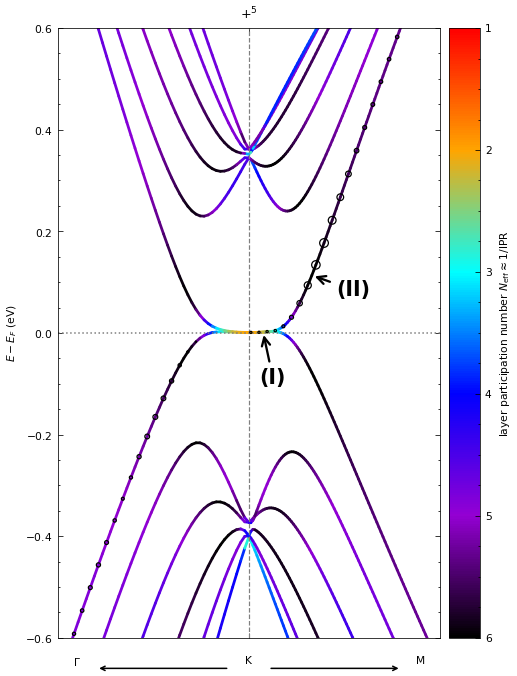

In [6]:
# panel a: (+5), ABCABC. Bands 23 and 24 (0-based) are the flat band and its dispersive part.
plot_bands('ABCABC',
           mapping={24: 's_flat_hi', 23: 's_flat_lo'},
           path_rules={24: ('K-M', 4), 23: ('G-K', 2)},
           marks=[{'k_idx': 407, 'band': 24, 'label': '(I)', 'offset': (-5, -75)},
                  {'k_idx': 431, 'band': 24, 'label': '(II)', 'offset': (35, -30)}],
           title='$+^{5}$')
plt.show()

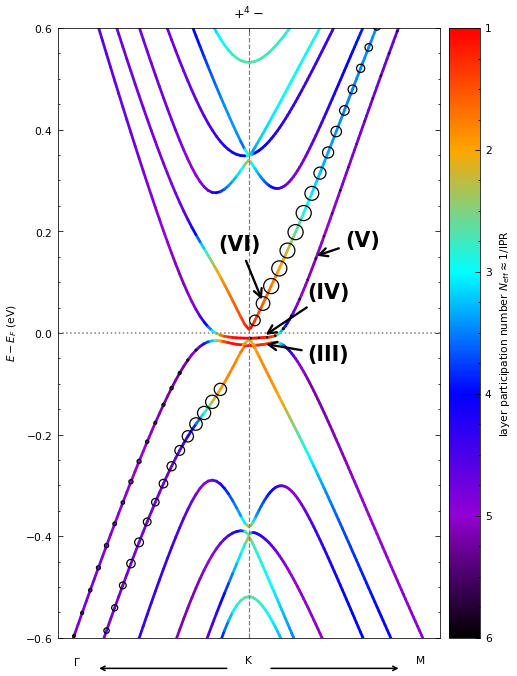

In [7]:
# panel b: (+4-), ABCABA (files: CBCABC). Bands 22 and 25 are the Dirac cone, 23 and 24 the buried flat band.
plot_bands('CBCABC',
           mapping={22: 's_lin_lo', 23: 's_flat_lo', 24: 's_flat_hi', 25: 's_lin_hi'},
           path_rules={25: ('K-M', 4), 22: ('G-K', 2), 24: ('K-M', 4), 23: ('G-K', 2)},
           marks=[{'k_idx': 407, 'energy': -0.021, 'label': '(III)', 'offset': (65, -25)},
                  {'k_idx': 407, 'energy': -0.007, 'label': '(IV)', 'offset': (65, 55)},
                  {'k_idx': 407, 'energy': 0.06, 'label': '(VI)', 'offset': (-65, 75)},
                  {'k_idx': 432, 'energy': 0.15, 'label': '(V)', 'offset': (45, 15)}],
           title='$+^{4}-$')
plt.show()

## Panels I-VI: planar-averaged charge densities

`PLANAR_AVERAGE.dat`: z (Å) and ρ(z) (e/Å³). The z axis is referenced to the bottom layer
(z₀ = 8.087 Å) and the layers are 3.315 Å apart. Densities 1 and 2 belong to the (+⁵) states I and II,
densities 3-6 to the (+⁴−) states III-VI. The stacking letters on the right axis give the stacking position of each layer.

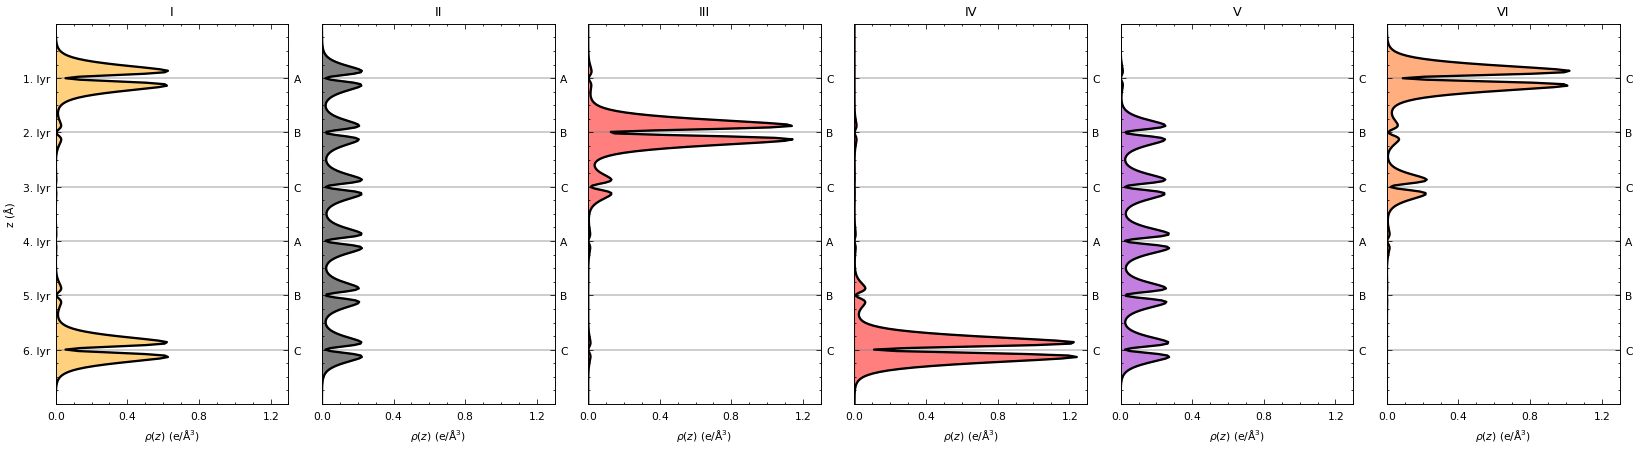

In [8]:
Z0, DZ = 8.08713, 3.315
DENSITIES = [('density1', 'I', '#ffa500', 'ABCABC'), ('density2', 'II', '#000000', 'ABCABC'),
             ('density3', 'III', 'red', 'CBCABC'), ('density4', 'IV', 'red', 'CBCABC'),
             ('density5', 'V', '#8800c2', 'CBCABC'), ('density6', 'VI', '#ff6000', 'CBCABC')]
# stacking letters from the bottom (layer 6) to the top (layer 1) layer, per stacking
LAYER_LETTERS = {'ABCABC': ['C', 'B', 'A', 'C', 'B', 'A'],   # (+5), states I and II
                 'CBCABC': ['C', 'B', 'A', 'C', 'B', 'C']}   # (+4-), states III-VI
yticks = [n * DZ for n in range(6)]

fig, axs = plt.subplots(1, 6, figsize=(15, 4.2), sharey=True)
for ax, (name, label, color, stacking) in zip(axs, DENSITIES):
    data = np.loadtxt(get_data(f'{name}_PLANAR_AVERAGE.dat'))
    z, rho = data[:, 0] - Z0, data[:, 1]
    ax.fill_betweenx(z, 0, rho, color=color, alpha=0.5)
    ax.plot(rho, z, color='black', lw=1.5)
    ax.set_xlim(0, 1.3); ax.set_ylim(-DZ, 6 * DZ)
    ax.set_title(label)
    ax.xaxis.set_major_locator(MultipleLocator(0.4))
    ax.set_xlabel(r'$\rho(z)$ (e/Å$^3$)')
    ax.set_yticks(yticks); ax.set_yticklabels([f'{6 - n}. lyr' for n in range(6)])
    ax.yaxis.grid(True, lw=1.0, color='gray', alpha=0.5)
    ax2 = ax.twinx()
    ax2.set_ylim(ax.get_ylim()); ax2.set_yticks(yticks); ax2.set_yticklabels(LAYER_LETTERS[stacking])
axs[0].set_ylabel('z (Å)')
plt.tight_layout()
plt.show()

## Panel c: energy-resolved reflection probability

`refl.dat`: energy (eV), R(E) for incidence from the (+⁵) side (blue), R(E) for incidence from the
(+⁴−) side (red), with the graphene lead coupled to the top layer. R(E) = 1 − I_out/I_in is normalized
to a reference calculation without the wall. In the figure negative values are clipped to zero;
they come from the re-reflection of the wall-reflected packet at the lead contact, which the
reference does not remove. Both the clipped and the raw curves are shown here.

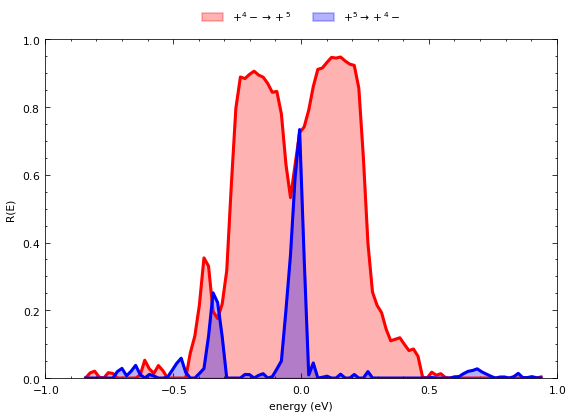

In [9]:
data = np.loadtxt(get_data('refl.dat'))
E_r, R_blue_raw, R_red_raw = data[:, 0], data[:, 1], data[:, 2]
label_red = r'$+^{4}- \rightarrow +^{5}$'
label_blue = r'$+^{5} \rightarrow +^{4}-$'

fig, ax = plt.subplots(figsize=(6, 4))
for R_raw, color, label in ((R_red_raw, 'red', label_red), (R_blue_raw, 'blue', label_blue)):
    R = np.maximum(R_raw, 0)
    ax.fill_between(E_r, 0, R, color=color, alpha=0.3, label=label)
    ax.plot(E_r, R, color=color, lw=2)
ax.set_xlim(-1, 1); ax.set_ylim(0, 1)
ax.set_xlabel('energy (eV)'); ax.set_ylabel('R(E)')
ax.xaxis.set_major_locator(MultipleLocator(0.5)); ax.yaxis.set_major_locator(MultipleLocator(0.2))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
plt.show()